In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
sns.set_theme(style="whitegrid")

c = pd.read_csv("../data/processed/manali_model.csv", index_col="Date", parse_dates=True)
y = c["AQI"].asfreq("D")
n = len(y); i1, i2 = int(n * 0.70), int(n * 0.85)
train, val, test = y.iloc[:i1], y.iloc[i1:i2], y.iloc[i2:]
for name, p in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:11s} {p.index[0].date()} to {p.index[-1].date()}  {len(p)} days")

train       2017-10-15 to 2018-11-26  408 days
validation  2018-11-27 to 2019-02-22  88 days
test        2019-02-23 to 2019-05-21  88 days


In [2]:
def metrics(actual, pred):
    a, p = np.asarray(actual, float), np.asarray(pred, float)
    return {"MAE": np.mean(np.abs(a - p)),
            "RMSE": np.sqrt(np.mean((a - p) ** 2)),
            "sMAPE %": 100 * np.mean(2 * np.abs(a - p) / (np.abs(a) + np.abs(p)))}

def persistence(idx):  return y.shift(1).loc[idx]                  # tomorrow = today
def moving_avg(idx):   return y.shift(1).rolling(7).mean().loc[idx]  # mean of the last 7 days

rows = {}
for name, f in [("persistence", persistence), ("7-day mean", moving_avg)]:
    rows[name] = metrics(val, f(val.index))
pd.DataFrame(rows).T.round(2)

,MAE,RMSE,sMAPE %
persistence,50.38,72.64,29.86
7-day mean,73.97,86.78,45.82


In [3]:
def one_step(order, fit_end, idx):
    """Fit on y[:fit_end], keep the parameters fixed, forecast each day in idx one step ahead."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = ARIMA(y.iloc[:fit_end], order=order).fit()
        full = res.apply(y)                       # same parameters, applied to the longer series
        return res, full.get_prediction(start=idx[0], end=idx[-1], dynamic=False).predicted_mean

rows = []
for p in range(0, 4):
    for q in range(0, 3):
        if p == 0 and q == 0:
            continue
        try:
            res, pred = one_step((p, 0, q), i1, val.index)
            rows.append({"order": (p, 0, q), "AIC": res.aic, **{f"val {k}": v for k, v in metrics(val, pred).items()}})
        except Exception as e:
            rows.append({"order": (p, 0, q), "AIC": np.nan, "val MAE": np.nan, "val RMSE": np.nan, "val sMAPE %": np.nan})
grid = pd.DataFrame(rows).sort_values("val MAE").reset_index(drop=True)
display(grid.round(2))

,order,AIC,val MAE,val RMSE,val sMAPE %
0,"(2, 0, 0)",4270.34,49.62,66.96,30.00
1,"(2, 0, 1)",4268.06,49.68,66.13,30.47
2,"(1, 0, 1)",4266.82,49.69,66.76,30.40
3,"(1, 0, 2)",4267.36,50.06,65.92,30.80
4,"(2, 0, 2)",4257.35,50.45,64.87,31.49
5,"(3, 0, 0)",4266.36,50.61,66.85,31.13
6,"(3, 0, 1)",4256.99,50.67,65.38,31.63
7,"(3, 0, 2)",4258.59,50.73,65.37,31.68
8,"(1, 0, 0)",4280.23,50.92,66.74,30.67
9,"(0, 0, 2)",4289.70,54.34,71.25,34.81


In [4]:
best = grid.loc[0, "order"]
print("Chosen order:", best)
res, pred_val = one_step(best, i1, val.index)
print(res.summary().tables[1])
print(acorr_ljungbox(res.resid, lags=[7, 14], return_df=True).round(3))

Chosen order: (2, 0, 0)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        115.8152     10.229     11.322      0.000      95.767     135.864
ar.L1          0.8409      0.030     27.951      0.000       0.782       0.900
ar.L2         -0.1712      0.039     -4.443      0.000      -0.247      -0.096
sigma2      2011.3581     96.160     20.917      0.000    1822.887    2199.829
    lb_stat  lb_pvalue
7     7.156      0.413
14   18.316      0.193


,MAE,RMSE,sMAPE %,skill vs persistence
persistence,24.38,40.79,17.80,0.00
7-day mean,31.07,46.39,23.76,-0.27
"ARIMA(2, 0, 0)",25.71,36.99,20.08,-0.05


Alerts (AQI > 200 = Poor or worse):
{'persistence': {'event days': 5, 'caught': 2, 'missed': 3, 'false alarms': 3}, 'ARIMA': {'event days': 5, 'caught': 2, 'missed': 3, 'false alarms': 2}}


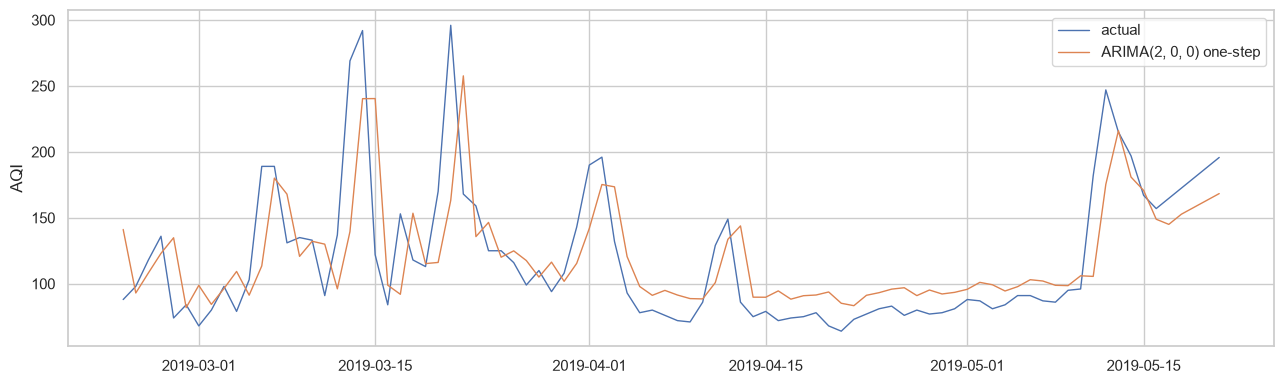

In [5]:
_, pred_test = one_step(best, i2, test.index)          # refit on train + validation, then forecast the test period

res_tab = {"persistence": metrics(test, persistence(test.index)),
           "7-day mean":  metrics(test, moving_avg(test.index)),
           f"ARIMA{best}": metrics(test, pred_test)}
tab = pd.DataFrame(res_tab).T
tab["skill vs persistence"] = 1 - tab["MAE"] / tab.loc["persistence", "MAE"]
display(tab.round(2))

def alerts(actual, pred, thr=200):
    a, p = np.asarray(actual) > thr, np.asarray(pred) > thr
    return {"event days": int(a.sum()), "caught": int((a & p).sum()),
            "missed": int((a & ~p).sum()), "false alarms": int((~a & p).sum())}
print("Alerts (AQI > 200 = Poor or worse):")
print({"persistence": alerts(test, persistence(test.index)), "ARIMA": alerts(test, pred_test)})

plt.figure(figsize=(13, 4))
plt.plot(test.index, test, label="actual", lw=1)
plt.plot(test.index, pred_test, label=f"ARIMA{best} one-step", lw=1)
plt.legend(); plt.ylabel("AQI")
plt.tight_layout(); plt.savefig("../figures/04_arima_test.png", dpi=150); plt.show()

In [6]:
out = pd.DataFrame({"actual": test, "persistence": persistence(test.index), "arima": pred_test})
out.to_csv("../data/processed/preds_test_arima.csv")
print("Saved", out.shape)

Saved (88, 3)
